<a href="https://colab.research.google.com/github/AliPatrick71/AI-Science-Engineering/blob/main/week5_supervised_machine_learning_bitcoin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment: Building My First Supervised Machine Learning Model
## AI for Science and Engineering — Bitcoin Price Direction

### Project question
Can recent Bitcoin (BTC-USD) market information help classify whether the next 15-minute closing price will be higher than the current closing price?

This notebook trains and compares two supervised classification models using historical 15-minute Bitcoin market data:
1. **Logistic Regression** — a linear classification model.
2. **Random Forest Classifier** — an ensemble of decision trees.

The notebook uses a chronological train/test split due to the fact that financial observations are time-ordered. The test set represents later observations that the models do not see during training.

## 1. Import libraries and download the dataset

The dataset contains Open, High, Low, Close, and Volume (OHLCV) values. Yahoo Finance's available intraday history can change, so the exact results may differ each time the notebook is run.

In [1]:
%pip -q install yfinance scikit-learn

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

ticker = "BTC-USD"
data = yf.download(
    ticker,
    period="60d",
    interval="15m",
    auto_adjust=False,
    progress=False
)

if data.empty:
    raise ValueError(
        "No data was returned. Check your internet connection and try again, "
        "or load the BTC-USD OHLCV CSV dataset used in Week 3."
    )

# Yahoo Finance may return a MultiIndex for column names.
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.reset_index()
data.columns = [str(c).lower().replace(" ", "_") for c in data.columns]

required = {"close", "high", "low", "open", "volume"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Expected OHLCV columns are missing: {missing}")

print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())

Dataset shape: (5726, 7)
Columns: ['datetime', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


,datetime,adj_close,close,high,low,open,volume
0,2026-08-29 00:00:00+00:00,77812.476562,77812.476562,77870.937500,77781.210938,77839.187500,120557568
1,2026-08-29 00:15:00+00:00,77901.671875,77901.671875,77950.312500,77808.687500,77812.476562,120414208
2,2026-08-29 00:30:00+00:00,77784.750000,77784.750000,77897.703125,77767.648438,77897.703125,88735744
3,2026-08-29 00:45:00+00:00,77734.476562,77734.476562,77819.398438,77715.742188,77784.742188,0
4,2026-08-29 01:00:00+00:00,77632.781250,77632.781250,77724.992188,77631.023438,77717.867188,0


## 2. Define the target and input features

**Target/output (`y`):** `target_up`, a binary label for the next 15-minute interval:
- `1` means the next closing price is higher than the current closing price.
- `0` means the next closing price is unchanged or lower.

**Features (`X`):** current Open, High, Low, Close, Volume, recent returns, simple moving averages, and a 14-period RSI.

The target uses the next interval's close, but that future value is **not** included in the feature matrix. The predictors are calculated from the current and past observations. The final row is removed because its next-period outcome is not yet known.

In [3]:
# Feature engineering based on current and historical observations.
data["return_1"] = data["close"].pct_change()
data["return_4"] = data["close"].pct_change(4)
data["sma_4"] = data["close"].rolling(4).mean()
data["sma_16"] = data["close"].rolling(16).mean()

# Simple 14-period RSI.
delta = data["close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
relative_strength = gain / loss.replace(0, np.nan)
data["rsi_14"] = 100 - (100 / (1 + relative_strength))

# Future close is used only to create the label, never as a predictor.
data["next_close"] = data["close"].shift(-1)
data["target_up"] = (data["next_close"] > data["close"]).astype(int)

feature_columns = [
    "open", "high", "low", "close", "volume",
    "return_1", "return_4", "sma_4", "sma_16", "rsi_14"
]

model_data = data.dropna(subset=feature_columns + ["next_close"]).copy()
model_data = model_data.reset_index(drop=True)

X = model_data[feature_columns]
y = model_data["target_up"]

print("Number of usable observations:", len(model_data))
print("Number of features:", len(feature_columns))
print("Target counts (0 = unchanged/down, 1 = up):")
display(y.value_counts().sort_index().rename_axis("target").to_frame("count"))
print("Target proportions:")
display(y.value_counts(normalize=True).sort_index().rename_axis("target").to_frame("proportion"))

Number of usable observations: 5710
Number of features: 10
Target counts (0 = unchanged/down, 1 = up):


,count
target,
0,2892
1,2818


Target proportions:


,proportion
target,
0,0.50648
1,0.49352


## 3. Split into training and test sets

Because this is time-series data, we will **not shuffle** the rows. The earlier 80% of observations are used for training, and the latest 20% are held out for testing. This better reflects the task of training on historical data and evaluating on later data.

- **Training set:** used to learn model parameters and patterns.
- **Test set:** used for final evaluation on observations not used to fit the models.

In [4]:
split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print(f"Training observations: {len(X_train):,} ({len(X_train)/len(model_data):.1%})")
print(f"Test observations: {len(X_test):,} ({len(X_test)/len(model_data):.1%})")
if "datetime" in model_data.columns:
    print("Training period:", model_data["datetime"].iloc[0], "to", model_data["datetime"].iloc[split_index - 1])
    print("Test period:", model_data["datetime"].iloc[split_index], "to", model_data["datetime"].iloc[-1])
print("The test set contains the latest observations and is kept separate from model fitting.")

Training observations: 4,568 (80.0%)
Test observations: 1,142 (20.0%)
Training period: 2026-08-29 03:45:00+00:00 to 2026-10-15 17:30:00+00:00
Test period: 2026-10-15 17:45:00+00:00 to 2026-10-27 15:00:00+00:00
The test set contains the latest observations and is kept separate from model fitting.


## 4. Create and train two supervised models

### Model 1: Logistic Regression
Logistic Regression estimates the probability of a binary outcome. We use a pipeline that fills any remaining missing feature values with their median and standardizes features before fitting. Scaling is especially useful for Logistic Regression because the features have different units and magnitudes.

### Model 2: Random Forest Classifier
A Random Forest combines many decision trees. It can learn nonlinear relationships and interactions between features. It does not require feature standardization, but we use median imputation for consistency.

Both models are trained only on the training set.

In [5]:
logistic_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

random_forest_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models have been trained.")

Both models have been trained.


## 5. Make predictions on unseen test data

Each trained model predicts the class for every row in the test set. The test labels are only used afterward to evaluate how well the predictions match the observed outcomes.

In [6]:
logistic_predictions = logistic_model.predict(X_test)
forest_predictions = random_forest_model.predict(X_test)

prediction_preview = pd.DataFrame({
    "actual_target": y_test.to_numpy(),
    "logistic_prediction": logistic_predictions,
    "random_forest_prediction": forest_predictions
}, index=y_test.index)

display(prediction_preview.head(10))

,actual_target,logistic_prediction,random_forest_prediction
4568,0,0,1
4569,1,0,1
4570,1,0,1
4571,1,1,1
4572,1,1,0
4573,1,0,0
4574,0,0,1
4575,0,0,0
4576,0,0,1
4577,1,0,1


## 6. Evaluate both models

We will use the classification metrics covered in class:

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** among predictions of an upward move, the proportion that were actually upward moves.
- **Recall:** among actual upward moves, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.

The positive class (`1`) means the next close is higher. Accuracy alone may be misleading if the target classes are imbalanced, so we compare all four metrics.

In [7]:
def classification_metrics(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision (up=1)": precision_score(actual, predicted, zero_division=0),
        "Recall (up=1)": recall_score(actual, predicted, zero_division=0),
        "F1-score (up=1)": f1_score(actual, predicted, zero_division=0)
    }

results = pd.DataFrame([
    classification_metrics("Logistic Regression", y_test, logistic_predictions),
    classification_metrics("Random Forest", y_test, forest_predictions)
]).set_index("Model")

display(results.round(4))

,Accuracy,Precision (up=1),Recall (up=1),F1-score (up=1)
Model,,,,
Logistic Regression,0.5254,0.5054,0.5146,0.5099
Random Forest,0.5219,0.5017,0.5274,0.5142


## 7. Confusion matrices and classification reports

A confusion matrix shows the counts of correct and incorrect predictions:
- **True negative (TN):** correctly predicted no upward move.
- **False positive (FP):** predicted an upward move when there was none.
- **False negative (FN):** missed an actual upward move.
- **True positive (TP):** correctly predicted an upward move.

These details help show which kinds of errors each model makes.

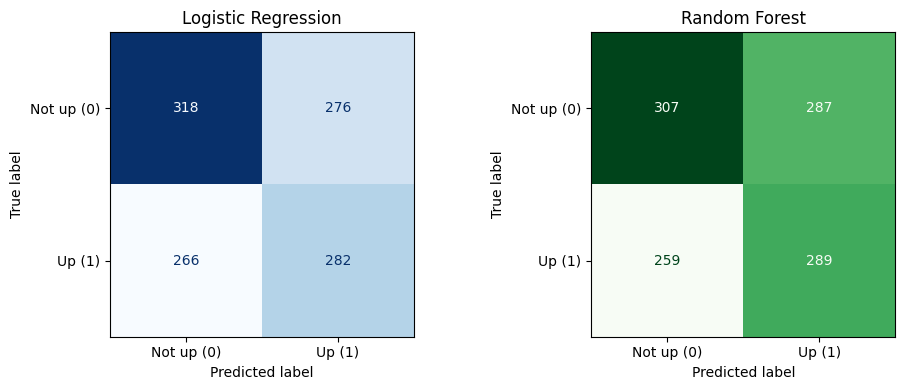

Logistic Regression classification report
              precision    recall  f1-score   support

           0       0.54      0.54      0.54       594
           1       0.51      0.51      0.51       548

    accuracy                           0.53      1142
   macro avg       0.52      0.52      0.52      1142
weighted avg       0.53      0.53      0.53      1142

Random Forest classification report
              precision    recall  f1-score   support

           0       0.54      0.52      0.53       594
           1       0.50      0.53      0.51       548

    accuracy                           0.52      1142
   macro avg       0.52      0.52      0.52      1142
weighted avg       0.52      0.52      0.52      1142



In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions,
    labels=[0, 1],
    display_labels=["Not up (0)", "Up (1)"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, forest_predictions,
    labels=[0, 1],
    display_labels=["Not up (0)", "Up (1)"],
    cmap="Greens",
    colorbar=False,
    ax=axes[1]
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

print("Logistic Regression classification report")
print(classification_report(y_test, logistic_predictions, zero_division=0))

print("Random Forest classification report")
print(classification_report(y_test, forest_predictions, zero_division=0))

## 8. Compare the models and discuss the results

Run the notebook and use the metrics table and confusion matrices to complete the discussion below. Do not assume that either model is best before inspecting the results.

- **Better overall results:** identify which model has the stronger F1-score and compare its accuracy, precision, and recall with the other model.
- **Types of errors:** use the confusion matrices to explain whether either model makes more false-positive or false-negative predictions.
- **Generalization:** these results are measured on a later holdout period, which gives a more realistic check than evaluating only on training data.
- **Limitations:** market direction is noisy and may be difficult to predict. Results can change with the selected time period, market conditions, and feature choices. A model with a higher score does not automatically produce profitable trades; transaction costs, slippage, and risk are not included.

For a short evidence-based conclusion, state the metric values from your run and say which model performed better on the test set according to the metric you consider most relevant. If scores are close, say so rather than claiming a large difference.

## 9. Conclusion

This project is a **supervised binary classification** problem since the model learns from labelled historical examples and predicts one of two classes: upward move (`1`) or no upward move (`0`) over the next 15 minutes.

The notebook follows the supervised learning workflow:
1. Define features (`X`) and target (`y`).
2. Split observations chronologically into training and test sets.
3. Train Logistic Regression and Random Forest models.
4. Predict on unseen test observations.
5. Evaluate and compare using accuracy, precision, recall, F1-score, and confusion matrices.

